# Powder PDF with DISCUS: generate, inspect and run a calculation

This notebook generates an inspectable DISCUS 1D PDF macro, optionally runs it, and plots the result. **You need DISCUS_SUITE installed separately.**

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from discuspdf import PDFConfig, PDFRunner

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print("Project root:", ROOT)

Project root: /home/user/discus_nb10/repo


## 1. Define calculation

The example GaAs unit-cell file was adapted from a published DISCUS file-format example. Replace it with your validated `.cll` file if needed.

In [3]:
# PDFConfig parameters (all Q in Å⁻¹, r in Å)
#   structure    unit-cell file (.cll)
#   supercell    crystal size in unit cells, e.g. (5, 5, 5)
#   rmax, dr     r range 0..rmax and step (rmax must be a whole number of dr steps)
#   qmin, qmax   Q range of the powder pattern (defaults 0.5 and 25; qmax must be > 0)
#   dq           Q step (default 0.01)
#   qsig         DISCUS `set delta` convolution width (default 0)
#   radiation    "xray" (default) or "neutron"
#   wavelength   Å; default 1.5406 (X-ray) or 1.5400 (neutron); e.g. 0.7107 for Mo Kα
#
# Qmax limit: DISCUS 6.23.01 uses Q only up to about 12.3/λ (≈ 8 Å⁻¹ at 1.5406 Å). A larger qmax runs but gives
# the same G(r), and PDFConfig warns (QmaxLimitWarning, shown below). For a higher Qmax, shorten the wavelength
# (qmax = 15 needs λ ≤ 0.82 Å); note that above Q ≈ 8 Å⁻¹ the DISCUS result varies with λ by a few percent.
config = PDFConfig(
    structure=ROOT / "examples" / "gaas.cll",
    supercell=(5, 5, 5),
    rmax=12.0,
    dr=0.02,
    qmax=25.0,
    qsig=0.0,
    radiation="xray",
)
runner = PDFRunner(runs_directory=ROOT / "runs")

/tmp/ipykernel_493/1875220557.py:1: QmaxLimitWarning: qmax = 25 Å⁻¹ is above what DISCUS 6.23.01 can use at wavelength 1.5406 Å (about 8.0 Å⁻¹). The calculation runs unchanged, but its G(r) is the same as for Qmax ≈ 8.0 Å⁻¹. A shorter explicit wavelength raises the limit, but above Q ≈ 8 Å⁻¹ the DISCUS result then depends on the wavelength by up to several percent (see docs/VERIFIED_DISCUS_MACRO.md, 'Qmax limit and wavelength').
  config = PDFConfig(


## 2. Inspect the generated macro before running

In [4]:
prepared = runner.prepare(config)
print((prepared.directory / "run.mac").read_text())

# Generated by discuspdf: 1D atomic PDF calculation (DISCUS v6.x)
discus
read
cell model.cll,5,5,5
powder
reset
xray
set axis,q
set calc,debye
set qmin,0.5
set qmax,25
set dq,0.01
set delta,0
set wvle,1.5406
run
exit
output
outf result.pdf
form pdf, r, 0.0, 12, 0.02
value PDF
run
exit
exit



## 3. Execute the inspected calculation

Switch `RUN_DISCUS` to True only after verifying the macro works with your installed executable and version.

`runner.execute(prepared)` runs **exactly the macro inspected in section 2** (its staged files and hashes are re-verified before launch). Use `runner.run(new_config)` only for *new* configurations, which prepares a fresh run directory first. The sweep in section 4 therefore uses `runner.run(replace(config, ...))`.

Saved: /home/user/discus_nb10/repo/runs/20261031T233236Z_0c06087d/result.pdf


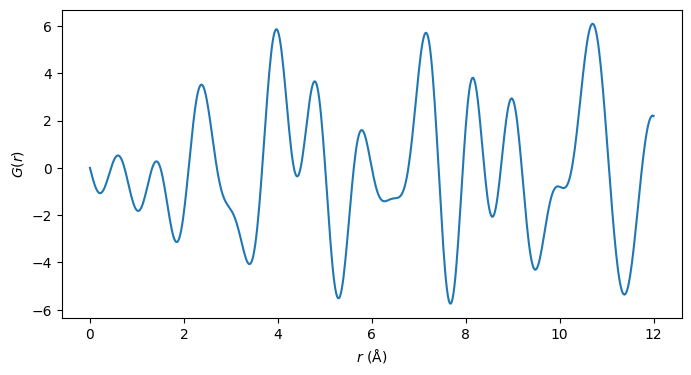

In [5]:
RUN_DISCUS = True  # enabled after validating the macro against DISCUS_SUITE 6.23.01
if RUN_DISCUS:
    result = runner.execute(prepared)
    print("Saved:", result.output)
    result.plot()
    plt.show()

## 4. Sweep Qmax and compare curves

Every run has its own directory, including logs and parameter metadata.

**Qmax limit.** DISCUS 6.23.01 cannot use Q above about 12.3/λ, i.e. about 8.0 Å⁻¹ at the default X-ray wavelength of 1.5406 Å. Larger values, including the `qmax=25` used above, still run, but give the same G(r) as Qmax ≈ 8, and `PDFConfig` issues a `QmaxLimitWarning` for them. The sweep below therefore shows Qmax 4, 6 and 7.5 Å⁻¹ (below the limit; the curves differ) and 25 Å⁻¹ (above it; the same curve as Qmax ≈ 8). A shorter explicit wavelength raises the limit, but above Q ≈ 8 Å⁻¹ the DISCUS result then depends on the wavelength. See `docs/VERIFIED_DISCUS_MACRO.md`, "Qmax limit and wavelength".

/tmp/ipykernel_493/3691027190.py:5: QmaxLimitWarning: qmax = 25 Å⁻¹ is above what DISCUS 6.23.01 can use at wavelength 1.5406 Å (about 8.0 Å⁻¹). The calculation runs unchanged, but its G(r) is the same as for Qmax ≈ 8.0 Å⁻¹. A shorter explicit wavelength raises the limit, but above Q ≈ 8 Å⁻¹ the DISCUS result then depends on the wavelength by up to several percent (see docs/VERIFIED_DISCUS_MACRO.md, 'Qmax limit and wavelength').
  run = runner.run(replace(config, qmax=qmax))


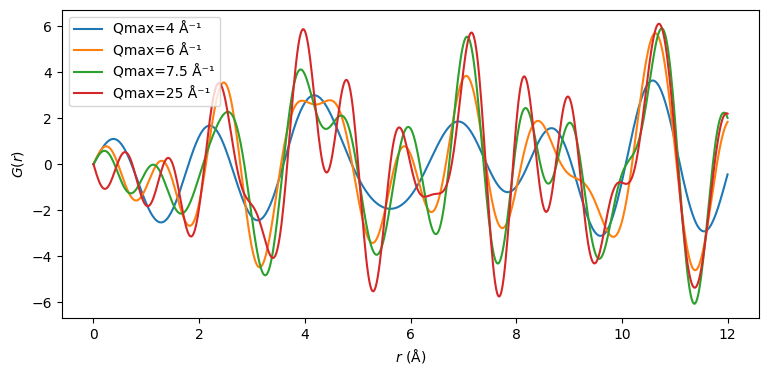

In [6]:
from dataclasses import replace
if RUN_DISCUS:
    fig, ax = plt.subplots(figsize=(9, 4))
    for qmax in (4.0, 6.0, 7.5, 25.0):
        run = runner.run(replace(config, qmax=qmax))
        run.plot(ax=ax, label=f"Qmax={qmax:g} Å⁻¹")
    plt.show()